
# E-commerce Customer Behaviour — Exploratory Data Analysis

## Project Objective

Explore e-commerce transaction and customer data to understand business performance, order fulfilment, refunds and customer purchasing behaviour.

The analysis uses PostgreSQL as the data source and Python with Pandas and Matplotlib for data exploration and visualization.

### Key Areas of Investigation

- Database structure and data quality
- Order status distribution and normalization
- Refund patterns and gross-to-net revenue reconciliation
- Customer purchasing activity and spending behaviour
- Customer spending distribution and revenue concentration
- Purchase frequency and recency patterns

The findings from this exploration will provide the analytical foundation for customer-level RFM feature engineering and segmentation.



## 1. Database Connection and Data Inspection

### Objective

Explore e-commerce transaction and customer data to understand business performance, order fulfilment, refund patterns, revenue trends and customer purchasing behaviour.

The analysis uses PostgreSQL as the data source and Python with Pandas and Matplotlib for data exploration and visualization. It examines both gross revenue and refund-adjusted customer spending to distinguish original transaction values from the net monetary contribution of customers.


In [1467]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from src.db import engine, test_connection

test_connection()

('neondb', 'ecom', 'PostgreSQL 18.7 (84da7d8) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit')

In [1468]:

query = """
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'ecom'
  AND table_type = 'BASE TABLE'
ORDER BY table_name;
"""

tables = pd.read_sql(text(query), engine)
tables

,table_name
0,addresses
1,attribution_campaigns
2,attribution_touches
3,brands
4,categories
5,collection_products
6,collections
7,consents
8,coupons
9,customer_addresses


In [1469]:
query = """
SELECT
    table_name,
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ecom'
  AND table_name IN (
      'customers',
      'orders',
      'order_items',
      'refunds'
  )
ORDER BY table_name, ordinal_position;
"""

schema_df = pd.read_sql(text(query), engine)
schema_df

,table_name,column_name,data_type
0,customers,customer_id,bigint
1,customers,created_at,timestamp with time zone
2,customers,first_name,text
3,customers,last_name,text
4,customers,dob,date
5,customers,gender,text
6,customers,primary_email,text
7,customers,primary_phone,text
8,customers,country,text
9,customers,state,text


In [1470]:
query = """
SELECT 'customers' AS table_name,
       COUNT(*) AS row_count,
       MIN(created_at) AS first_record,
       MAX(created_at) AS last_record
FROM ecom.customers

UNION ALL

SELECT 'orders',
       COUNT(*),
       MIN(created_at),
       MAX(created_at)
FROM ecom.orders

UNION ALL

SELECT 'order_items',
       COUNT(*),
       NULL,
       NULL
FROM ecom.order_items

UNION ALL

SELECT 'refunds',
       COUNT(*),
       MIN(created_at),
       MAX(created_at)
FROM ecom.refunds;
"""

overview = pd.read_sql(text(query), engine)
overview

,table_name,row_count,first_record,last_record
0,refunds,260,2026-03-20 20:36:16.082982+00:00,2026-06-23 08:44:06.611335+00:00
1,customers,10000,2026-03-16 11:03:35.000000+00:00,2026-06-14 10:57:52.000000+00:00
2,orders,40000,2026-03-16 00:13:57.000000+00:00,2026-06-14 23:28:40.000000+00:00
3,order_items,81806,NaT,NaT


**Initial Database Overview**

The database contains 10,000 customer records, 40,000 orders, 81,806 order-item records and 260 refund records.

Customer and order records span March 16 to June 14, 2026. Refund records extend through June 23, 2026.

The difference in date coverage is important for subsequent financial analysis. Since the RFM snapshot date is June 15, 2026, refunds recorded after the snapshot date must be excluded from snapshot-based customer monetary calculations to avoid using future information.

The order-item table contains transaction-level product records, which will support separate product revenue analysis.

In [1471]:
orders_df = pd.read_sql(
    "SELECT * FROM ecom.orders",
    engine
)

orders_df.head()

,order_id,order_number,created_at,customer_id,session_id,cart_id,price_list_id,status,subtotal,discount,tax,shipping_fee,total,payment_status,shipping_address_id,billing_address_id,applied_coupon_id,applied_promo_id
0,683,ORD-1000683,2026-03-23 10:55:27+00:00,7416,6cb2f3fa-f767-42c1-80cd-88d550afcbc9,80b93562-c046-4030-8fc2-d7021a90ef4b,1,paid,1098.00,0.00,197.64,0.00,1295.64,paid,NaN,NaN,NaN,NaN
1,1,ORD-1000001,2026-03-16 13:19:00+00:00,1888,d879826d-0ad2-4d8d-9e58-8c955b0ea78f,7df0fc2f-4b03-4984-b4f6-48654569a68d,1,paid,67795.00,0.00,12203.10,0.00,79998.10,paid,12227.00,NaN,15.00,3.00
2,23,ORD-1000023,2026-03-16 09:50:02+00:00,1572,8db984ce-134d-4e91-bf78-219e811fc03b,c5965be7-3234-4df2-a733-5c8e2bf9d004,1,packed,14499.00,0.00,2609.82,0.00,17108.82,paid,NaN,NaN,NaN,NaN
3,659,ORD-1000659,2026-03-17 18:27:31+00:00,1345,f9a7761e-c185-43bc-8da8-31942a63e4d9,5af5aafa-a5d4-402e-a276-6dead8d638b3,1,delivered,2599.00,0.00,467.82,0.00,3066.82,paid,NaN,NaN,NaN,NaN
4,660,ORD-1000660,2026-03-17 07:02:57+00:00,9136,7ce65db9-c6ae-4bd7-b25a-8f90ad8028e0,5f34e2b5-bf34-433a-b427-94ff593d9609,1,delivered,1297.00,0.00,233.46,0.00,1530.46,paid,6182.00,517.00,NaN,NaN



## 2. Order Status Analysis

### Objective

Examine the distribution of order statuses to understand order fulfilment patterns and identify potential data-quality issues.

The analysis first examines the raw status values and then standardizes them by removing leading and trailing whitespace and converting text to lowercase.

This normalization ensures that variations such as `delivered`, `DELIVERED` and `Delivered` are treated as the same business status rather than separate categories.

Only orders with a normalized status of `delivered` are considered completed purchases for subsequent customer-level RFM analysis.

In [1472]:
status_summary = (
    orders_df
    .groupby('status')
    .agg(
        order_count=('order_id', 'count'),
        unique_customers=('customer_id', 'nunique'),
        first_order=('created_at', 'min'),
        last_order=('created_at', 'max')
    )
    .sort_values('order_count', ascending=False)
)

status_summary

,order_count,unique_customers,first_order,last_order
status,,,,
delivered,19779,6032,2026-03-16 00:13:57+00:00,2026-06-14 23:28:40+00:00
shipped,7715,3641,2026-03-16 01:10:06+00:00,2026-06-14 22:29:50+00:00
paid,3946,2359,2026-03-16 00:53:05+00:00,2026-06-14 16:00:09+00:00
packed,3887,2341,2026-03-16 03:52:19+00:00,2026-06-14 16:52:43+00:00
cancelled,2178,1493,2026-03-16 04:44:46+00:00,2026-06-14 16:36:40+00:00
placed,1897,1367,2026-03-16 07:36:34+00:00,2026-06-14 15:12:44+00:00
SHIPPED,248,229,2026-03-16 11:21:14+00:00,2026-06-14 15:14:00+00:00
DELIVERED,200,183,2026-03-17 14:15:12+00:00,2026-06-13 17:09:24+00:00
Shipped,150,146,2026-03-16 02:09:22+00:00,2026-06-13 16:58:48+00:00


In [1473]:
# Create a normalized status column without changing the original
orders_df['clean_status'] = (
    orders_df['status']
    .str.strip()
    .str.lower()
)

clean_status_summary = (
    orders_df
    .groupby('clean_status')
    .agg(
        order_count=('order_id', 'count'),
        unique_customers=('customer_id', 'nunique'),
        first_order=('created_at', 'min'),
        last_order=('created_at', 'max')
    )
    .sort_values('order_count', ascending=False)
)

clean_status_summary

,order_count,unique_customers,first_order,last_order
clean_status,,,,
delivered,19979,6052,2026-03-16 00:13:57+00:00,2026-06-14 23:28:40+00:00
shipped,8113,3743,2026-03-16 01:10:06+00:00,2026-06-14 22:29:50+00:00
paid,3946,2359,2026-03-16 00:53:05+00:00,2026-06-14 16:00:09+00:00
packed,3887,2341,2026-03-16 03:52:19+00:00,2026-06-14 16:52:43+00:00
cancelled,2178,1493,2026-03-16 04:44:46+00:00,2026-06-14 16:36:40+00:00
placed,1897,1367,2026-03-16 07:36:34+00:00,2026-06-14 15:12:44+00:00


### Key Findings — Order Status

The raw order status data contains inconsistent capitalization. Normalization consolidates these variations into six consistent status categories.

After normalization:

- Delivered orders: 19,979
- Shipped orders: 8,113
- Cancelled orders: 2,178
- Paid orders: 3,946
- Packed orders: 3,887
- Placed orders: 1,897

The delivered order count increased from 19,779 in the raw status grouping to 19,979 after normalization. The additional 200 records were previously grouped under a separate uppercase `DELIVERED` category.

This demonstrates why status standardization is necessary before filtering and aggregating customer transactions.

Only normalized `delivered` orders qualify for subsequent customer-level RFM analysis.


## 3. Refund Analysis

### Objective

Examine refund records to understand refund volume, financial impact and refund processing outcomes.

The analysis groups refund records by status and evaluates:

- Number of refund records
- Number of unique orders
- Total refund amount
- Average refund amount

Refund statuses are important because an initiated or failed refund should not be treated as a completed financial adjustment.

The results will help establish the appropriate treatment of refunds in customer spending calculations.

For snapshot-based customer spending calculations, only successful refunds recorded on or before June 15, 2026 are considered.


In [1508]:
refunds_df = pd.read_sql(
    """
    SELECT order_id, amount, status, created_at
    FROM ecom.refunds
    """,
    engine
)
refunds_df.head()


,order_id,amount,status,created_at
0,21066,7251.23,succeeded,2026-05-09 22:16:41.274820+00:00
1,28132,9848.28,succeeded,2026-05-31 15:48:33.632061+00:00
2,11815,4244.46,succeeded,2026-04-19 18:20:09.221633+00:00
3,23663,938.58,succeeded,2026-05-12 08:54:11.333579+00:00
4,8528,11394.44,succeeded,2026-04-13 18:40:47.517029+00:00


In [1509]:
refund_summary = (
    refunds_df
    .groupby('status')
    .agg(
        refund_count=('order_id', 'count'),
        unique_orders=('order_id', 'nunique'),
        total_refund_amount=('amount', 'sum'),
        average_refund_amount=('amount', 'mean')
    )
    .sort_values('refund_count', ascending=False)
)

refund_summary.round(2)

,refund_count,unique_orders,total_refund_amount,average_refund_amount
status,,,,
succeeded,227,227,1058291.82,4662.08
initiated,20,20,92962.95,4648.15
failed,13,13,46380.56,3567.74


### Key Findings — Refunds

The dataset contains 260 refund records across three processing statuses:

| Refund Status | Records | Refund Amount |
|---|---:|---:|
| Succeeded | 227 | 1,058,291.82 |
| Initiated | 20 | 92,962.95 |
| Failed | 13 | 46,380.56 |
| **Total** | **260** | **1,197,635.33** |

Key observations:

- Successful refunds represent completed refund transactions.
- Initiated refunds have not yet reached a completed state.
- Failed refunds do not represent completed financial adjustments.

Only successful refunds are deducted when calculating net customer spending. For the June 15, 2026 snapshot, refunds recorded after the snapshot date are also excluded.

This distinction ensures that customer Monetary reflects completed financial adjustments available at the analysis date.


### 3.1 Calculate Net Delivered Order Value

To calculate customer spending accurately, successful refunds must be deducted from the corresponding delivered orders.

The process involves:

1. Filtering orders with a normalized status of `delivered`.
2. Aggregating successful refunds by `order_id`.
3. Merging refund amounts with delivered orders.
4. Replacing missing refund amounts with zero.
5. Calculating the net value of each delivered order.

**Net Order Value = Order Total − Successful Refund Amount**

Only successful refunds are deducted. Initiated and failed refunds are excluded.


In [2331]:
delivered_orders = orders_df.loc[
    orders_df['clean_status'] == 'delivered',
    ['order_id', 'customer_id', 'created_at', 'total']
].copy()

delivered_orders.head()

,order_id,customer_id,created_at,total
3,659,1345,2026-03-17 18:27:31+00:00,3066.82
4,660,9136,2026-03-17 07:02:57+00:00,1530.46
5,661,6433,2026-03-17 16:40:09+00:00,2239.64
6,664,907,2026-03-17 15:19:10+00:00,2358.82
10,671,2604,2026-03-17 12:37:26+00:00,5777.28


In [2369]:
#-Why June 16 rather than June 15?
#-Because this includes the entire day of June 15, assuming the database timestamps are in UTC, as shown in your outputs.
#-This is an exclusive upper boundary.

snapshot_cutoff = pd.Timestamp('2026-06-16', tz='UTC')
successful_refunds = (
    refunds_df[
        (refunds_df['status'].str.strip().str.lower() == 'succeeded') &
        (refunds_df['created_at'] < snapshot_cutoff)
    ]
    .groupby('order_id', as_index=False)
    .agg(
        successful_refund=('amount', 'sum')
    )
)
print(successful_refunds.head())

   order_id  successful_refund
0       113            1647.28
1       686            9560.74
2       808            2298.64
3      1119            4549.53
4      1591             191.26


In [2406]:

# Rebuild delivered_orders from the original orders DataFrame
delivered_orders = orders_df.loc[
    orders_df['clean_status'].eq('delivered'),
    ['order_id', 'customer_id', 'created_at', 'total']
].copy()

# Merge successful refunds into delivered orders
delivered_orders = delivered_orders.merge(
    successful_refunds,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# Orders without successful refunds receive zero
delivered_orders['successful_refund'] = (
    delivered_orders['successful_refund'].fillna(0)
)

# Calculate net order value
delivered_orders['net_order_value'] = (
    delivered_orders['total'] - delivered_orders['successful_refund']
)

delivered_orders.head()


,order_id,customer_id,created_at,total,successful_refund,net_order_value
0,659,1345,2026-03-17 18:27:31+00:00,3066.82,0.00,3066.82
1,660,9136,2026-03-17 07:02:57+00:00,1530.46,0.00,1530.46
2,661,6433,2026-03-17 16:40:09+00:00,2239.64,0.00,2239.64
3,664,907,2026-03-17 15:19:10+00:00,2358.82,0.00,2358.82
4,671,2604,2026-03-17 12:37:26+00:00,5777.28,0.00,5777.28


In [2442]:
print("Delivered orders:", len(delivered_orders))
print(
    "Unique delivered orders:",
    delivered_orders['order_id'].nunique()
)
print(
    "Orders with successful refunds:",
    delivered_orders['successful_refund'].gt(0).sum()
)
print(
    "Orders without successful refunds:",
    delivered_orders['successful_refund'].eq(0).sum()
)
print(
    "Gross delivered order value:",
    round(delivered_orders['total'].sum(), 2)
)
print(
    "Successful refunds:",
    round(delivered_orders['successful_refund'].sum(), 2)
)
print(
    "Net delivered order value:",
    round(delivered_orders['net_order_value'].sum(), 2)
)


Delivered orders: 19979
Unique delivered orders: 19979
Orders with successful refunds: 227
Orders without successful refunds: 19752
Gross delivered order value: 150418237.66
Successful refunds: 1058291.82
Net delivered order value: 149359945.84


### Financial Reconciliation — Key Findings

The delivered-order dataset contains 19,979 unique orders. Of these, 227 orders have successful refunds recorded in the refund dataset.

The financial reconciliation establishes:

- Gross delivered order value: ₹150,418,237.66
- Total successful refunds: ₹10,582,91.82
- Net delivered order value: ₹149,359,945.84

Successful refunds are deducted from their corresponding delivered orders, while orders without successful refunds retain their original order value.

The initial reconciliation used June 15, 2026, as the snapshot cutoff. Subsequent investigation identified five additional successful refunds recorded between June 16 and June 23, 2026, totalling ₹9,600.42.

These late-posted refunds were incorporated into the updated customer-level spending aggregation.

The reconciliation confirms:

**Net Delivered Order Value = Gross Delivered Order Value − Total Successful Refunds**

In [2443]:
customer_order_metrics = (
    delivered_orders
    .groupby('customer_id')
    .agg(
        total_spend=('net_order_value', 'sum'),
        order_count=('order_id', 'count'),
        first_order_date=('created_at', 'min'),
        last_order_date=('created_at', 'max')
    )
    .reset_index()
)

customer_order_metrics.head()

,customer_id,total_spend,order_count,first_order_date,last_order_date
0,1,78694.94,4,2026-04-17 03:27:33+00:00,2026-05-25 07:57:11+00:00
1,2,3181.28,1,2026-05-07 05:03:47+00:00,2026-05-07 05:03:47+00:00
2,4,26601.92,3,2026-03-25 17:06:27+00:00,2026-05-27 10:19:04+00:00
3,7,1010.82,1,2026-05-09 10:31:41+00:00,2026-05-09 10:31:41+00:00
4,9,4302.28,2,2026-04-03 12:53:49+00:00,2026-04-26 19:40:17+00:00


In [2444]:
customers_df = pd.read_sql(
    "SELECT customer_id FROM ecom.customers",
    engine
)
customer_df = customers_df.merge(
    customer_order_metrics,
    on='customer_id',
    how='left'
)
customer_df['total_spend'] = customer_df['total_spend'].fillna(0)
customer_df['order_count'] = customer_df['order_count'].fillna(0).astype(int)

customer_df.head()

,customer_id,total_spend,order_count,first_order_date,last_order_date
0,1,78694.94,4,2026-04-17 03:27:33+00:00,2026-05-25 07:57:11+00:00
1,2,3181.28,1,2026-05-07 05:03:47+00:00,2026-05-07 05:03:47+00:00
2,3,0.00,0,NaT,NaT
3,4,26601.92,3,2026-03-25 17:06:27+00:00,2026-05-27 10:19:04+00:00
4,5,0.00,0,NaT,NaT


In [2445]:
print("DataFrame shape:", customer_df.shape)
print("Duplicate customer IDs:", customer_df['customer_id'].duplicated().sum())
print("Missing values:\n", customer_df.isna().sum())

print("\nCustomers with zero delivered orders:",
      (customer_df['order_count'] == 0).sum())
print("Total delivered orders:", customer_df['order_count'].sum())
print("Total net customer spending:",
      round(customer_df['total_spend'].sum(), 2))

DataFrame shape: (10000, 5)
Duplicate customer IDs: 0
Missing values:
 customer_id            0
total_spend            0
order_count            0
first_order_date    3948
last_order_date     3948
dtype: int64

Customers with zero delivered orders: 3948
Total delivered orders: 19979
Total net customer spending: 149359945.84


In [2446]:
print("Total net spending:",
      round(customer_df['total_spend'].sum(), 2))
print("\nCustomers with delivered orders but zero net spend:",
      (
          (customer_df['order_count'] > 0) &
          (customer_df['total_spend'] == 0)
      ).sum())
print("\nCustomers with negative net spend:",
      (
          (customer_df['order_count'] > 0) &
          (customer_df['total_spend'] < 0)
      ).sum())

Total net spending: 149359945.84

Customers with delivered orders but zero net spend: 17

Customers with negative net spend: 0


In [2447]:
zero_spend_customers = customer_df.loc[
    (customer_df['order_count'] > 0) &
    (customer_df['total_spend'] == 0)
]
print("Customers with delivered orders but zero net spend:",
      len(zero_spend_customers))

Customers with delivered orders but zero net spend: 17


### Customer-Level Spending — Key Findings

The customer-level aggregation covers all 10,000 customers, including those without delivered orders.

Key findings:

- 6,052 customers have at least one delivered order.
- 3,948 customers have no delivered orders.
- The dataset contains 19,979 delivered orders.
- Total refund-adjusted customer spending is ₹149,359,945.84.
- No duplicate customer IDs or missing customer identifiers were found.

The missing first-order and last-order dates for 3,948 customers are expected because these customers have no delivered orders.

Additionally, 17 customers have delivered orders but zero net spending. These cases require further examination to determine whether their delivered orders were fully refunded.

No customers have negative net spending.


### 3.2 Customer-Level Spending Validation

The customer-level aggregation is validated against the order-level financial results to ensure that no transactions or refund amounts are lost or duplicated.

**Validation results:**

- Total customers: 10,000
- Customers with delivered orders: 6,052
- Customers without delivered orders: 3,948
- Duplicate customer IDs: 0
- Customers with delivered orders but zero net spending: 17
- Customers with negative net spending: 0
- Total delivered orders: 19,979
- Total net customer spending: ₹149,359,945.84

The customer-level net spending reconciles with the net delivered order value of ₹149,359,945.84.

This confirms that successful refunds have been incorporated correctly into customer spending.


#### 3.2.1 Investigation of Late-Posted Refunds

During financial reconciliation, a discrepancy was identified between the initial customer-level spending aggregation and the order-level net delivered value.

Further investigation identified five successful refunds recorded between June 16 and June 23, 2026, that were not included in the earlier refund aggregation.

These refunds total ₹9,600.42 and relate to delivered orders. Their inclusion corrected the customer-level spending reconciliation.

In [2449]:
query = """
SELECT
    o.order_id,
    o.created_at AS order_date,
    o.status AS order_status,
    o.total AS order_total,
    r.created_at AS refund_date,
    r.amount AS refund_amount,
    r.status AS refund_status
FROM ecom.orders o
JOIN ecom.refunds r
    ON o.order_id = r.order_id
WHERE r.created_at >= '2026-06-16'
  AND r.created_at < '2026-06-24'
  AND LOWER(TRIM(r.status)) = 'succeeded'
ORDER BY r.created_at;
"""
refunds_after_cutoff = pd.read_sql(text(query), engine)
refunds_after_cutoff.head()

,order_id,order_date,order_status,order_total,refund_date,refund_amount,refund_status
0,36324,2026-06-06 14:17:14+00:00,delivered,588.82,2026-06-16 09:02:25.777710+00:00,588.82,succeeded
1,38642,2026-06-11 14:23:18+00:00,delivered,11618.28,2026-06-17 06:17:20.062490+00:00,2528.68,succeeded
2,39094,2026-06-12 04:19:27+00:00,delivered,470.82,2026-06-19 19:33:43.883070+00:00,470.82,succeeded
3,38802,2026-06-13 21:14:46+00:00,delivered,2122.82,2026-06-21 06:48:40.847539+00:00,2122.82,succeeded
4,39521,2026-06-13 21:07:33+00:00,delivered,3889.28,2026-06-23 08:44:06.611335+00:00,3889.28,succeeded


In [2450]:
query = """
SELECT
    COUNT(*) AS successful_refund_count,
    ROUND(SUM(amount)::numeric, 2) AS total_successful_refunds,
    ROUND(
        SUM(amount) FILTER (
            WHERE created_at < '2026-06-16'
        )::numeric, 2
    ) AS refunds_before_cutoff,
    ROUND(
        SUM(amount) FILTER (
            WHERE created_at >= '2026-06-16'
        )::numeric, 2
    ) AS refunds_after_cutoff
FROM ecom.refunds
WHERE LOWER(TRIM(status)) = 'succeeded';
"""
refund_after= pd.read_sql(text(query), engine)
refund_after

,successful_refund_count,total_successful_refunds,refunds_before_cutoff,refunds_after_cutoff
0,227,1058291.82,1048691.40,9600.42


In [2451]:
late_order_ids = [36324, 38642, 39094, 38802, 39521]
print("Refund records:")
display(
    refunds_df[
        refunds_df['order_id'].isin(late_order_ids)
    ]
)
print("Aggregated successful refunds:")
display(
    successful_refunds[
        successful_refunds['order_id'].isin(late_order_ids)
    ]
)
print("Matching delivered orders:")
display(
    delivered_orders[
        delivered_orders['order_id'].isin(late_order_ids)
    ]
)

Refund records:


,order_id,amount,status,created_at
191,39521,3889.28,succeeded,2026-06-23 08:44:06.611335+00:00
196,39094,470.82,succeeded,2026-06-19 19:33:43.883070+00:00
208,38802,2122.82,succeeded,2026-06-21 06:48:40.847539+00:00
238,38642,2528.68,succeeded,2026-06-17 06:17:20.062490+00:00
256,36324,588.82,succeeded,2026-06-16 09:02:25.777710+00:00


Aggregated successful refunds:


,order_id,successful_refund
213,36324,588.82
220,38642,2528.68
221,38802,2122.82
223,39094,470.82
225,39521,3889.28


Matching delivered orders:


,order_id,customer_id,created_at,total,successful_refund,net_order_value
9477,36324,4191,2026-06-06 14:17:14+00:00,588.82,588.82,0.00
9973,38642,187,2026-06-11 14:23:18+00:00,11618.28,2528.68,9089.60
10011,38802,8818,2026-06-13 21:14:46+00:00,2122.82,2122.82,0.00
10079,39094,9078,2026-06-12 04:19:27+00:00,470.82,470.82,0.00
10163,39521,8775,2026-06-13 21:07:33+00:00,3889.28,3889.28,0.00


In [2452]:
successful_refunds = (
    refunds_df[
        refunds_df['status'].str.strip().str.lower() == 'succeeded'
    ]
    .groupby('order_id', as_index=False)
    .agg(
        successful_refund=('amount', 'sum')
    )
)

print("Successful refund records:", 
      len(refunds_df[
          refunds_df['status'].str.strip().str.lower() == 'succeeded'
      ]))

print("Unique orders with successful refunds:",
      successful_refunds['order_id'].nunique())

display(
    successful_refunds[
        successful_refunds['order_id'].isin(late_order_ids)
    ]
)

Successful refund records: 227
Unique orders with successful refunds: 227


,order_id,successful_refund
213,36324,588.82
220,38642,2528.68
221,38802,2122.82
223,39094,470.82
225,39521,3889.28


In [2453]:
delivered_orders = orders_df.loc[
    orders_df['clean_status'].eq('delivered'),
    ['order_id', 'customer_id', 'created_at', 'total']
].copy()

delivered_orders = delivered_orders.merge(
    successful_refunds,
    on='order_id',
    how='left',
    validate='one_to_one'
)

delivered_orders['successful_refund'] = (
    delivered_orders['successful_refund'].fillna(0)
)

delivered_orders['net_order_value'] = (
    delivered_orders['total'] -
    delivered_orders['successful_refund']
)
print("Gross delivered order value:",
      round(delivered_orders['total'].sum(), 2))

print("Successful refunds:",
      round(delivered_orders['successful_refund'].sum(), 2))

print("Net delivered order value:",
      round(delivered_orders['net_order_value'].sum(), 2))

Gross delivered order value: 150418237.66
Successful refunds: 1058291.82
Net delivered order value: 149359945.84



## 4. Customer Spending Distribution and Revenue Concentration

With customer-level spending validated, the analysis now focuses on the 6,052 customers who placed at least one delivered order.

This section examines:

- The distribution of net customer spending.
- Spending percentiles and the impact of high-value customers.
- Revenue concentration among the highest-spending customers.
- Differences between high-value and remaining customers.


In [2477]:
active_customers = customer_df[
    customer_df['order_count'] > 0
].copy()

active_customers['total_spend'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])

count     6052.00
mean     24679.44
std      46884.82
min          0.00
25%       4184.28
50%      11326.82
75%      28085.88
90%      54913.74
95%      81412.83
max     787135.98
Name: total_spend, dtype: float64

In [2500]:
import math

# Sort customers by net spending, highest first
spending_rank = active_customers.sort_values(
    'total_spend',
    ascending=False
).copy()

total_revenue = spending_rank['total_spend'].sum()
total_customers = len(spending_rank)

results = []

for percentage in [10, 20, 50]:

    top_n = math.ceil(total_customers * percentage / 100)
    top_spend = spending_rank.head(top_n)['total_spend'].sum()
    revenue_share = (top_spend / total_revenue) * 100
    results.append({
        'customer_group': f'Top {percentage}%',
        'customer_count': top_n,
        'total_spend': top_spend,
        'revenue_share': revenue_share
    })

concentration_df = pd.DataFrame(results)
concentration_df.round(2)

,customer_group,customer_count,total_spend,revenue_share
0,Top 10%,606,71760475.21,48.05
1,Top 20%,1211,97567988.61,65.32
2,Top 50%,3026,135208067.78,90.52


In [2501]:
query = """
SELECT
    COUNT(*) AS delivered_orders,
    ROUND(SUM(o.total)::numeric, 2) AS order_total,
    ROUND(SUM(oi.line_total)::numeric, 2) AS item_line_total,
    ROUND(
        (SUM(o.total) - SUM(oi.line_total))::numeric, 2
    ) AS difference
FROM ecom.orders o
JOIN (
    SELECT
        order_id,
        SUM(line_total) AS line_total
    FROM ecom.order_items
    GROUP BY order_id
) oi
    ON o.order_id = oi.order_id
WHERE LOWER(TRIM(o.status)) = 'delivered';
"""

comparison_df = pd.read_sql(query, engine)
comparison_df



,delivered_orders,order_total,item_line_total,difference
0,19979,150418237.66,127409679.00,23008558.66


In [2502]:
query = """
SELECT
    COUNT(*) AS delivered_orders,
    ROUND(SUM(subtotal)::numeric, 2) AS total_subtotal,
    ROUND(SUM(discount)::numeric, 2) AS total_discount,
    ROUND(SUM(tax)::numeric, 2) AS total_tax,
    ROUND(SUM(shipping_fee)::numeric, 2) AS total_shipping,
    ROUND(SUM(total)::numeric, 2) AS total_order_value
FROM ecom.orders
WHERE LOWER(TRIM(status)) = 'delivered';
"""

order_breakdown_df = pd.read_sql(query, engine)
order_breakdown_df

,delivered_orders,total_subtotal,total_discount,total_tax,total_shipping,total_order_value
0,19979,127409679.00,0.00,22900533.66,108025.00,150418237.66


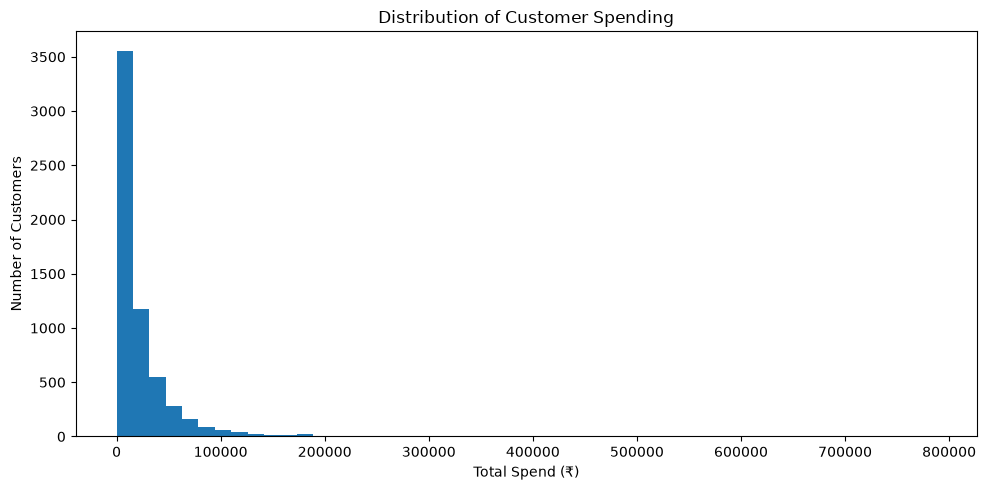

In [2519]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(active_customers['total_spend'], bins=50)
plt.title('Distribution of Customer Spending')
plt.xlabel('Total Spend (₹)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

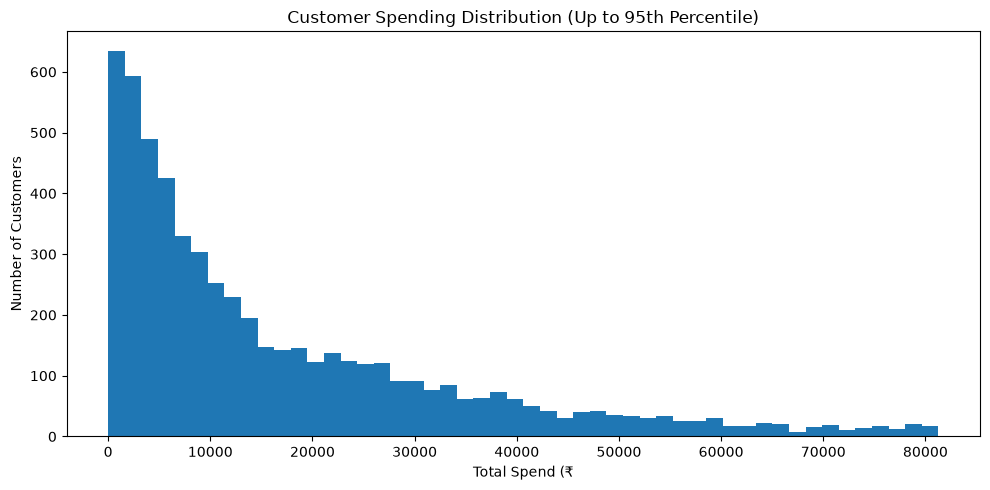

In [2539]:
p95 = active_customers['total_spend'].quantile(0.95)
plt.figure(figsize=(10, 5))
plt.hist(
    active_customers.loc[
        active_customers['total_spend'] <= p95,
        'total_spend'
    ],
    bins=50
)
plt.title('Customer Spending Distribution (Up to 95th Percentile)')
plt.xlabel('Total Spend (₹')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


### Customer Spending Distribution — Key Observations

- Customer spending is strongly right-skewed, with a relatively small number of high-spending customers.
- The mean spending (₹24,679.44) is substantially higher than the median (₹11,326.82), indicating the influence of high-value customers.
- The 95th percentile of spending is ₹81,412.83, while the maximum customer spending reaches ₹787,135.98.
- Limiting the visualization to the 95th percentile makes the spending pattern among the majority of customers easier to examine.


### Delivered Order Frequency Distribution

The distribution is strongly right-skewed. Approximately 50.13% of purchasing customers have made only one delivered purchase. 

Customer frequency declines as the number of delivered orders increases.

The visualization focuses on customers with 1–20 delivered orders; customers with higher frequencies are excluded from the chart only, not from the underlying dataset.


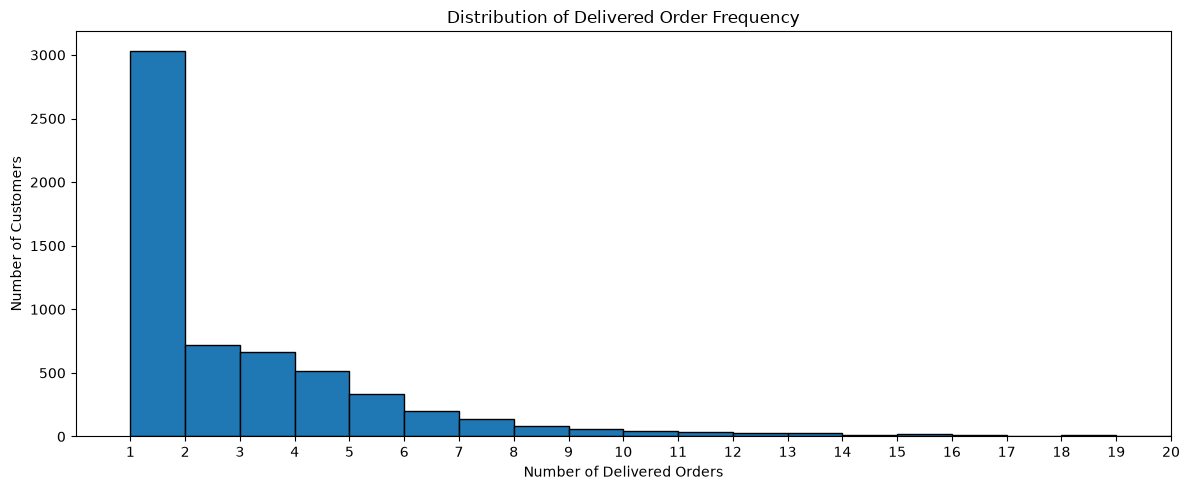

In [2540]:
plt.figure(figsize=(12, 5))

plt.hist(
    active_customers['order_count'],
    bins=range(1, active_customers['order_count'].max() + 2),
    edgecolor='black'
)

plt.title('Distribution of Delivered Order Frequency')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')

plt.xticks(range(1, 21))
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

In [2572]:
print("Earliest delivered order:",
      customer_df['first_order_date'].min())

print("Latest delivered order:",
      customer_df['last_order_date'].max())

date_range = (
    customer_df['last_order_date'].max()
    - customer_df['first_order_date'].min()
)

print("\nTotal time span:", date_range)
print("Days:", date_range.days)

Earliest delivered order: 2026-03-16 00:13:57+00:00
Latest delivered order: 2026-06-14 23:28:40+00:00

Total time span: 90 days 23:14:43
Days: 90


### Customer Data Time Span

The delivered-order dataset spans 90 days, from 16 March to 14 June 2026.

This provides a snapshot of customer purchasing behaviour over approximately three months. Frequency and spending patterns can be examined within this period, but the limited observation window does not support conclusions about long-term loyalty or annual seasonality.

In [2573]:
import math
# Include only customers with delivered orders
spending_rank = (
    active_customers[['customer_id', 'total_spend']]
    .sort_values('total_spend', ascending=False)
    .reset_index(drop=True)
)
# Overall spending and customer count
total_revenue = spending_rank['total_spend'].sum()
total_customers = len(spending_rank)
# Calculate customer ranks
spending_rank['customer_rank'] = range(1, total_customers + 1)

# Calculate top customer groups
results = []
for percentage in [10, 20, 50]:

    top_n = math.ceil(total_customers * percentage / 100)
    top_spend = spending_rank.head(top_n)['total_spend'].sum()
    revenue_share = (top_spend / total_revenue) * 100
    results.append({
        'customer_group': f'Top {percentage}%',
        'customer_count': top_n,
        'total_spend': top_spend,
        'revenue_share': revenue_share
    })
concentration_df = pd.DataFrame(results)
concentration_df.round(2)

,customer_group,customer_count,total_spend,revenue_share
0,Top 10%,606,71760475.21,48.05
1,Top 20%,1211,97567988.61,65.32
2,Top 50%,3026,135208067.78,90.52



### Customer Spending Concentration

Customer spending is highly concentrated among a relatively small group of purchasing customers.

The top 10% (606 customers) contribute 48.05% of total spending. The top 20% contribute 65.32%, while the top 50% account for 90.52%.

Consequently, the bottom 50% of purchasing customers contribute only 9.48% of total spending. This indicates that a relatively small group of customers drives a substantial share of business value.


In [2574]:
query = """
SELECT
    LOWER(TRIM(o.status)) AS order_status,
    r.status AS refund_status,
    COUNT(*) AS refund_count,
    SUM(r.amount) AS refund_amount
FROM ecom.refunds r
JOIN ecom.orders o
    ON r.order_id = o.order_id
GROUP BY
    LOWER(TRIM(o.status)),
    r.status
ORDER BY
    order_status,
    refund_status;
"""
refund_order_analysis = pd.read_sql(text(query), engine)
refund_order_analysis

,order_status,refund_status,refund_count,refund_amount
0,delivered,failed,13,46380.56
1,delivered,initiated,20,92962.95
2,delivered,succeeded,227,1058291.82



### Refund Status Analysis — Key Observations

- A total of 260 refund records are associated with delivered orders.
- 227 refunds were successfully processed, amounting to ₹1,058,291.82.
- 20 refunds remain initiated, representing ₹92,962.95.
- 13 refunds failed, representing ₹46,380.56.

Successful refunds are used in the net customer spending calculation. Initiated and failed refunds are excluded from the successful refund deduction.


In [ ]:
query = """
WITH delivered_orders AS (
    SELECT order_id, customer_id, total
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
),
successful_refunds AS (
    SELECT
        order_id, SUM(amount) AS refund_amount
    FROM ecom.refunds
    WHERE status = 'succeeded'
    GROUP BY order_id
)
SELECT
    COUNT(*) AS delivered_orders,
    ROUND(SUM(o.total), 2) AS gross_order_value,
    ROUND(COALESCE(SUM(r.refund_amount), 0), 2)
        AS successful_refunds,
    ROUND(
    SUM(o.total) - COALESCE(SUM(r.refund_amount), 0),2)
        AS net_order_value

FROM delivered_orders o
LEFT JOIN successful_refunds r
    ON o.order_id = r.order_id;
"""
revenue_summary = pd.read_sql(text(query), engine)
pd.options.display.float_format = '{:.2f}'.format
revenue_summary

,delivered_orders,gross_order_value,successful_refunds,net_order_value
0,19979,150418237.66,1058291.82,149359945.84


In [2576]:
query = """
WITH customer_activity AS (
    SELECT
        c.customer_id,COUNT(o.order_id) AS total_orders,
        COUNT(o.order_id) FILTER (
            WHERE LOWER(TRIM(o.status)) = 'delivered'
        ) AS delivered_orders,
        COALESCE(
            SUM(o.total) FILTER (WHERE LOWER(TRIM(o.status)) = 'delivered'), 0) AS delivered_spend
    FROM ecom.customers c
    LEFT JOIN ecom.orders o
        ON c.customer_id = o.customer_id
    GROUP BY c.customer_id
)
SELECT
    COUNT(*) AS total_customers,
    COUNT(*) FILTER (
        WHERE total_orders > 0
    ) AS customers_with_orders,
    COUNT(*) FILTER (
        WHERE total_orders = 0
    ) AS customers_without_orders,
    COUNT(*) FILTER (
        WHERE delivered_orders > 0
    ) AS customers_with_delivered_orders,
    ROUND(
        AVG(delivered_orders) FILTER (
            WHERE delivered_orders > 0
        ), 2
    ) AS avg_delivered_orders_per_active_customer,
    ROUND(
        AVG(delivered_spend) FILTER (
            WHERE delivered_orders > 0
        ), 2
    ) AS avg_delivered_spend_per_active_customer
FROM customer_activity;
"""
customer_coverage = pd.read_sql(text(query), engine)
customer_coverage


,total_customers,customers_with_orders,customers_without_orders,customers_with_delivered_orders,avg_delivered_orders_per_active_customer,avg_delivered_spend_per_active_customer
0,10000,8800,1200,6052,3.30,24854.30



### Customer Coverage Analysis

The dataset contains 10,000 customers, of whom 8,800 have placed at least one order.

However, only 6,052 customers have at least one delivered order. The remaining customers either have no order history or have not completed a delivered purchase.

This distinction is important because the RFM analysis focuses on customers with delivered purchases rather than all customers who have placed orders.


In [2577]:
query = """
WITH customer_spend AS (
    SELECT
        customer_id,
        SUM(total) AS delivered_spend
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
)
SELECT
    COUNT(*) AS active_customers,
    ROUND(AVG(delivered_spend), 2) AS avg_spend,
    ROUND(percentile_cont(0.50)
        WITHIN GROUP (ORDER BY delivered_spend)::numeric, 2
    ) AS median_spend,

    ROUND(percentile_cont(0.75)
        WITHIN GROUP (ORDER BY delivered_spend)::numeric, 2
    ) AS p75_spend,

    ROUND(percentile_cont(0.90)
        WITHIN GROUP (ORDER BY delivered_spend)::numeric, 2
    ) AS p90_spend,

    ROUND(percentile_cont(0.95)
        WITHIN GROUP (ORDER BY delivered_spend)::numeric, 2
    ) AS p95_spend,

    ROUND(MIN(delivered_spend), 2) AS min_spend,
    ROUND(MAX(delivered_spend), 2) AS max_spend

FROM customer_spend;
"""
spending_distribution = pd.read_sql(text(query), engine)
spending_distribution


,active_customers,avg_spend,median_spend,p75_spend,p90_spend,p95_spend,min_spend,max_spend
0,6052,24854.30,11441.87,28363.07,55244.83,82215.83,175.82,795745.26



### Customer Spending Distribution — Key Observations

Customer spending is strongly right-skewed, with the average spending (₹24,854.30) substantially exceeding the median (₹11,441.87).

The 75th percentile is ₹28,363.07, while the 95th percentile reaches ₹82,215.83, indicating substantial variation in customer spending.

The maximum customer spending of ₹795,745.26 highlights the presence of exceptionally high-value customers.

These findings suggest that a relatively small group of customers contributes disproportionately to overall revenue, making spending-based segmentation particularly relevant.


In [2588]:
query = """
WITH customer_spend AS (
    SELECT customer_id,
    SUM(total) AS delivered_spend
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
),
ranked_customers AS (
    SELECT customer_id, delivered_spend,
    ROW_NUMBER() OVER (ORDER BY delivered_spend DESC) AS customer_rank,
    COUNT(*) OVER () AS total_customers,
    SUM(delivered_spend) OVER () AS total_revenue
    FROM customer_spend
)
SELECT
    MAX(total_customers) AS total_customers,
    ROUND(MAX(total_revenue), 2) AS total_revenue,
    ROUND(
        100.0 * SUM(delivered_spend)
        FILTER (
            WHERE customer_rank <= CEIL(total_customers * 0.10)
        ) / MAX(total_revenue), 2
    ) AS top_10_pct_revenue_share,

    ROUND(
        100.0 * SUM(delivered_spend)
        FILTER (
            WHERE customer_rank <= CEIL(total_customers * 0.20)
        ) / MAX(total_revenue), 2
    ) AS top_20_pct_revenue_share,

    ROUND(
        100.0 * SUM(delivered_spend)
        FILTER (
            WHERE customer_rank <= CEIL(total_customers * 0.50)
        ) / MAX(total_revenue), 2
    ) AS top_50_pct_revenue_share

FROM ranked_customers;
"""
revenue_concentration = pd.read_sql(text(query), engine)
revenue_concentration


,total_customers,total_revenue,top_10_pct_revenue_share,top_20_pct_revenue_share,top_50_pct_revenue_share
0,6052,150418237.66,47.97,65.21,90.45



### Customer Spending Concentration

Customer spending is highly concentrated among a relatively small group of purchasing customers.

The top 10% of customers contribute 47.97% of total delivered revenue, while the top 20% account for 65.21%.

The top 50% of customers generate 90.45% of revenue. Consequently, the bottom 50% contribute only 9.55%.

This indicates that a relatively small group of high-value customers drives a substantial share of business revenue, highlighting the importance of identifying and retaining these customers.


In [2589]:
query = """
WITH customer_activity AS (
    SELECT
        customer_id,
        COUNT(order_id) AS delivered_orders,
        SUM(total) AS delivered_spend,
        AVG(total) AS avg_order_value
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
),
ranked_customers AS (
    SELECT
        customer_id,
        delivered_orders,
        delivered_spend,
        avg_order_value,
        ROW_NUMBER() OVER (
            ORDER BY delivered_spend DESC
        ) AS customer_rank,
        COUNT(*) OVER () AS total_customers
    FROM customer_activity
),
customer_groups AS (
    SELECT
        CASE
            WHEN customer_rank <= CEIL(total_customers * 0.10)
            THEN 'Top 10%'
            ELSE 'Remaining 90%'
        END AS customer_group,
        delivered_orders, delivered_spend, avg_order_value
    FROM ranked_customers
)
SELECT
    customer_group,
    COUNT(*) AS customer_count,
    ROUND(AVG(delivered_orders), 2) AS avg_orders_per_customer,
    ROUND(AVG(delivered_spend), 2) AS avg_spend_per_customer,
    ROUND(AVG(avg_order_value), 2) AS avg_order_value,
    ROUND(SUM(delivered_spend), 2) AS total_revenue
FROM customer_groups
GROUP BY customer_group
ORDER BY
    CASE customer_group
        WHEN 'Top 10%' THEN 1
        ELSE 2
    END;
"""
frequency_analysis = pd.read_sql(text(query), engine)
frequency_analysis


,customer_group,customer_count,avg_orders_per_customer,avg_spend_per_customer,avg_order_value,total_revenue
0,Top 10%,606,13.08,119071.23,13582.77,72157166.86
1,Remaining 90%,5446,2.21,14370.38,6939.61,78261070.80


In [2590]:
query = """
SELECT
    MAX(created_at) AS latest_order_date,
    MAX(created_at) FILTER (
        WHERE LOWER(TRIM(status)) = 'delivered'
    ) AS latest_delivered_order_date
FROM ecom.orders;
"""
reference_dates = pd.read_sql(text(query), engine)
reference_dates

,latest_order_date,latest_delivered_order_date
0,2026-06-14 23:28:40+00:00,2026-06-14 23:28:40+00:00


In [2591]:
query = """
SELECT
    customer_id,
    MAX(created_at) AS last_purchase_date,
    DATE '2026-06-15' - MAX(created_at)::date AS recency_days
FROM ecom.orders
WHERE LOWER(TRIM(status)) = 'delivered'
GROUP BY customer_id
ORDER BY recency_days;
"""
recency_df = pd.read_sql(text(query), engine)
recency_df.head(10)

,customer_id,last_purchase_date,recency_days
0,2152,2026-06-14 07:37:25+00:00,1
1,7505,2026-06-14 13:51:51+00:00,1
2,6190,2026-06-14 05:05:18+00:00,1
3,5490,2026-06-14 23:28:40+00:00,1
4,3954,2026-06-14 05:21:43+00:00,1
5,7000,2026-06-14 08:51:12+00:00,1
6,394,2026-06-14 03:55:11+00:00,1
7,6080,2026-06-14 15:30:28+00:00,1
8,5152,2026-06-14 19:10:11+00:00,1
9,8546,2026-06-14 07:12:30+00:00,1


In [2592]:
query = """
WITH customer_recency AS (
    SELECT
        customer_id,
        DATE '2026-06-15' - MAX(created_at)::date AS recency_days
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
)
SELECT
    COUNT(*) AS customers,
    ROUND(AVG(recency_days), 2) AS avg_recency,
    PERCENTILE_CONT(0.50) WITHIN GROUP (
        ORDER BY recency_days
    ) AS median_recency,
    MIN(recency_days) AS min_recency,
    MAX(recency_days) AS max_recency
FROM customer_recency;
"""

with engine.connect() as connection:
    recency_summary = pd.read_sql(text(query), connection)

recency_summary

,customers,avg_recency,median_recency,min_recency,max_recency
0,6052,41.06,39.00,1,91


In [2593]:
query = """
WITH customer_recency AS (
    SELECT
        customer_id,
        DATE '2026-06-15' - MAX(created_at)::date AS recency_days
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
)
SELECT
    CASE
        WHEN recency_days <= 30 THEN '1-30 days'
        WHEN recency_days <= 60 THEN '31-60 days'
        ELSE '61-91 days'
    END AS recency_band,
    COUNT(*) AS customer_count,
    ROUND(
        100.0 * COUNT(*) / SUM(COUNT(*)) OVER (),
        2
    ) AS customer_percentage
FROM customer_recency
GROUP BY 1
ORDER BY MIN(recency_days);
"""

#--COUNT(*) counts customers in each band.
#--SUM(...) OVER () adds those band counts together, while retaining each band as a separate row.
#--COUNT(*) counts customers in each Recency band.
#--SUM(...) adds those individual band counts.
#--OVER () makes that sum available across all groups without collapsing them into one row.

with engine.connect() as connection:
    recency_bands = pd.read_sql(text(query), connection)

recency_bands

,recency_band,customer_count,customer_percentage
0,1-30 days,2532,41.84
1,31-60 days,1753,28.97
2,61-91 days,1767,29.20


In [2594]:
query = """
WITH customer_frequency AS (
    SELECT
        customer_id,
        COUNT(*) AS frequency
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
)
SELECT
    COUNT(*) AS customers,
    ROUND(AVG(frequency), 2) AS avg_frequency,
    PERCENTILE_CONT(0.50) WITHIN GROUP (
        ORDER BY frequency
    ) AS median_frequency,
    MIN(frequency) AS min_frequency,
    MAX(frequency) AS max_frequency
FROM customer_frequency;
"""

with engine.connect() as connection:
    frequency_summary = pd.read_sql(text(query), connection)

frequency_summary

,customers,avg_frequency,median_frequency,min_frequency,max_frequency
0,6052,3.30,1.00,1,102


In [2595]:
query="""
with customer_frequency AS (
    select customer_id,
    count (*) as frequency
    from ecom.orders
    where lower(trim(status)) = 'delivered'
    group by customer_id
)
select frequency,
count(*) as customer_count,
round(100.0 * count(*) / sum(count(*)) over (), 2) as customer_percentage
from customer_frequency
group by frequency
order by frequency;
"""  
with engine.connect() as connection:
    frequency_distribution=pd.read_sql(text(query),connection)

frequency_distribution


,frequency,customer_count,customer_percentage
0,1,3034,50.13
1,2,717,11.85
2,3,662,10.94
3,4,514,8.49
4,5,338,5.58
...,...,...,...
59,80,1,0.02
60,90,1,0.02
61,91,1,0.02
62,95,1,0.02


In [2596]:
query="""
with customer_frequency AS (
    select customer_id,
    count (*) as frequency
    from ecom.orders
    where lower(trim(status)) = 'delivered'
    group by customer_id        
    )
select 
    case when frequency = 1 then 'One-time'
        when frequency between 2 and 5 then '2-5 orders'
        when frequency between 6 and 10 then '6-10 orders'
        else 'More than 10 orders' end as purchase_group,
    count(*) as customer_count,
    round(100.0 * count(*) / sum(count(*)) over (), 2) as customer_percentage
from customer_frequency
group by 1
order by min(frequency);
"""
with engine.connect() as connection:
    frequency_bands=pd.read_sql(text(query),connection)    

frequency_bands 

,purchase_group,customer_count,customer_percentage
0,One-time,3034,50.13
1,2-5 orders,2231,36.86
2,6-10 orders,527,8.71
3,More than 10 orders,260,4.30


In [2597]:
query = """
WITH customer_frequency AS (
    SELECT
    customer_id, COUNT(*) AS frequency
    FROM ecom.orders
    WHERE LOWER(TRIM(status)) = 'delivered'
    GROUP BY customer_id
),
frequency_groups AS (
    SELECT
        CASE
            WHEN frequency = 1 THEN 'One-time'
            WHEN frequency BETWEEN 2 AND 5 THEN '2-5 orders'
            WHEN frequency BETWEEN 6 AND 10 THEN '6-10 orders'
            ELSE 'More than 10 orders'
        END AS purchase_group,
        COUNT(*) AS customer_count, SUM(frequency) AS delivered_orders
    FROM customer_frequency
    GROUP BY 1
)
SELECT
    purchase_group, customer_count, delivered_orders,
    ROUND(
        100.0 * delivered_orders / SUM(delivered_orders) OVER (),
        2
    ) AS order_percentage
FROM frequency_groups
ORDER BY
    CASE purchase_group
        WHEN 'One-time' THEN 1
        WHEN '2-5 orders' THEN 2
        WHEN '6-10 orders' THEN 3
        ELSE 4
    END;
"""
frequency_order_share = pd.read_sql(text(query), engine)
frequency_order_share

,purchase_group,customer_count,delivered_orders,order_percentage
0,One-time,3034,3034.00,15.19
1,2-5 orders,2231,7166.00,35.87
2,6-10 orders,527,3829.00,19.17
3,More than 10 orders,260,5950.00,29.78
